# Bài tập 2 — Đặc trưng góc & Phân vùng ảnh
**Môn:** Thị giác máy tính (121036) — Trường ĐH GTVT TP.HCM

**Nhóm:** N

| MSSV | Họ tên | Công việc |
|---|---|---|
| 051205011311 | Nguyễn Minh Hiển | Phần A (1/2): Harris cổ điển, ANMS (A2), kiểm chứng A1/A4/A5, TN2|
| 079205010059 | Nguyễn Quốc Hưng | Phần B (1/3): SRG lõi (lazy/frozen, phá hòa), kiểm chứng B1–B3|
| 066205015306 | Nguyễn Kha Rin   | Phần B (2/3): Region Growing cổ điển (stack/queue), kiểm chứng B4, TN3 (ngưỡng T)|
| 060205000948 | Lương Quốc Thắng | Phần B (3/3): `srg_step_frames`, `seed_sensitivity`, kiểm chứng B5, TN3 (SRG), ghép bài & Run All |
| 079205042179 | Nguyễn Đình Huy  | Phần A (2/2): Harris–Laplace (A1), repeatability, kiểm chứng A2/A3, TN1|

## 0. Khai báo sử dụng AI
- Phần cài đặt (mục A.1, B.1): **không dùng AI**.
- Phần thí nghiệm: mỗi cell có dùng AI đều có một cell markdown **ngay phía trên**, ghi `**Prompt đã dùng (nguyên văn):**` kèm prompt.

### Khai báo chi tiết của thành viên Nguyễn Kha Rin (Phần B — Region Growing & TN3)
Trong quá trình thực hiện bài tập lớn Computer Vision, em có sử dụng ChatGPT để hỗ trợ một số công việc:

**1. Phần B.1.1 – Region Growing cổ điển**
- Hỗ trợ hướng dẫn cài đặt thư viện Python và xử lý lỗi khi chạy Jupyter Notebook.
- Hỗ trợ kiểm tra môi trường thực thi và hướng dẫn chạy chương trình.
- Không sử dụng AI để viết thuật toán Region Growing cốt lõi.

**2. Phần B4 – So sánh Stack, Queue và SRG**
- Hỗ trợ hướng dẫn tích hợp hàm SRG do thành viên trong nhóm cung cấp.
- Hỗ trợ tạo dữ liệu thử nghiệm và đoạn mã tính số pixel khác nhau giữa ba phương pháp.
- Hỗ trợ phân tích và trình bày kết quả so sánh.

**3. Phần TN3 – Khảo sát ngưỡng T**
- Hỗ trợ phân tích bảng kết quả thực nghiệm.
- Hỗ trợ giải thích ảnh hưởng của ngưỡng T đến diện tích vùng phát triển và hiện tượng Region Leakage.
- Hỗ trợ trình bày kết quả và viết phần nhận xét, kết luận.

**Cam kết:** Em chịu trách nhiệm kiểm tra, chạy thử, đánh giá kết quả và hiểu nội dung chương trình trước khi đưa vào bài nộp. AI chỉ được sử dụng như công cụ hỗ trợ trong phạm vi nêu trên.

## Thiết lập chung

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math, time, heapq
from scipy.ndimage import gaussian_filter
import cv2

# Phần A — Harris và hai biến thể

## A.1 Cài đặt
> ⛔ **Cài đặt — KHÔNG dùng AI.** Toàn bộ cell dưới tiêu đề này do nhóm tự viết.

### A.1.1 Harris cổ điển
`gaussian_blur`, `structure_tensor`, `harris_response`, `nms_2d`, `harris_classic`

In [2]:
def gaussian_blur(img, sigma):
  """Làm mờ Gauss. Được phép gọi scipy.ndimage.gaussian_filter."""


  anh_thuc = img.astype(np.float64)
  ket_qua = gaussian_filter(anh_thuc, sigma=sigma)
  return ket_qua
  
def structure_tensor(img, sigma_i, sigma_d):
  """Ma trận mô-men bậc hai theo công thức (1), đã nhân sigma_d**2.
  sigma_d: độ mờ trước khi lấy đạo hàm.
  sigma_i: bán kính cửa sổ lấy trung bình các tích đạo hàm.-> (Mxx, Mxy, Myy), mỗi phần tử cùng kích thước ảnh.
  """
  anh_mo=gaussian_blur(img, sigma_d)
  Ly, Lx = np.gradient(anh_mo)
  Ixx = Lx * Lx
  Ixy = Lx * Ly
  Iyy = Ly * Ly
  Mxx = gaussian_blur(Ixx, sigma_i) *(sigma_d ** 2)
  Mxy = gaussian_blur(Ixy, sigma_i) *(sigma_d ** 2)
  Myy = gaussian_blur(Iyy, sigma_i) *(sigma_d ** 2)

  return Mxx, Mxy, Myy
def harris_response(img, sigma_i, sigma_d, k=0.04):
  """dap ung R theoo cong thuc (2). -> mang float cung kich thuoc anh."""
  Mxx, Mxy, Myy = structure_tensor( img, sigma_i, sigma_d)
  det = Mxx * Myy - Mxy ** 2
  trace = Mxx + Myy
  R = det - k * (trace ** 2)
  return R
def nms_2d(response, window = 3):
  """cuc dai dia phuong trong cua so window x window. -> mang bool"""
  H, W = response.shape # cao H, rong W
  pad = window // 2
  padded_response = np.pad(response, pad, mode='constant', constant_values=-np.inf)
  is_max = np.ones_like(response, dtype=bool)
  for dy in range(window):
    for dx in range(window):
      neighbor = padded_response[dy:dy+H, dx:dx+W]
      is_max = is_max & (response >= neighbor)
  return is_max
def harris_classic(img, sigma_i=2.0, sigma_d=1.4, k=0.04, thresh_rel=0.01):
  """Harris một tỉ lệ: R -> nms_2d -> ngưỡng tương đối theo max(R).-> mảng (N, 3): (row, col, response), sắp xếp giảm dần theo response."""
  R = harris_response(img, sigma_i, sigma_d, k)
  if R.max() <= 0:
    return np.zeros((0, 3), dtype=float)
  local_max = nms_2d(R, window=3)
  mask = local_max & ( R > thresh_rel * R.max())
  rows, cols = np.where(mask)
  scores = R[rows, cols]
  order = np.argsort(-scores )
  pts = np.column_stack([rows[order], cols[order], scores[order]])
  return pts


  


### A.1.2 Biến thể A1 — Harris–Laplace
`scale_pyramid`, `log_normalized`, `harris_laplace`

In [3]:
# TODO (tự viết): các hàm Harris–Laplace

### A.1.3 Biến thể A2 — ANMS
`anms`, `top_n`

In [4]:
def top_n(points, n_keep):
    """Đường cơ sở để so với anms: lấy n_keep điểm mạnh nhất.
    -> mảng (n_keep, 3).
    """
    order = np.argsort(-points[:, 2])
    return points[order[:n_keep]]
def anms(points, n_keep, c_robust=0.9):
    coords = points[:, :2]
    resp = points[:, 2]
    radii = np.full(len(points), np.inf)
    for i in range(len(points)):
        bigger = resp[i] < c_robust * resp
        if np.any(bigger):
            under = coords[bigger] - coords[i]
            radiis = np.sqrt(np.sum(under ** 2, axis=1))
            radii[i] = np.min(radiis)
    num_points = np.argsort(-radii)
    return points[num_points[:n_keep]]

### A.1.4 Đo đạc
`repeatability`

In [5]:
# TODO (tự viết): repeatability

### A.1.5 Hàm cho sẵn
`grid_occupancy` — dán nguyên hàm giảng viên cung cấp.

In [6]:
# Dán hàm grid_occupancy do giảng viên cung cấp
def grid_occupancy(points, img_shape, grid=(8, 8)):
    """Tỉ lệ ô lưới (grid[0] x grid[1]) có ít nhất một điểm."""
    H, W = img_shape[:2]
    gh, gw = grid
    occupied = set()
    for r, c in points[:, :2]:
        gr = min(int(r * gh / H), gh - 1)
        gc = min(int(c * gw / W), gw - 1)
        occupied.add((gr, gc))
    return len(occupied) / (gh * gw)

## A.2 Kiểm chứng cài đặt — Phần A

### 1. Bàn cờ tổng hợp — giao điểm trong, sai số ≤ 1 px


Tìm thấy 256 điểm | Sai số lớn nhất: 0.000 px | Đạt (<=1px): True


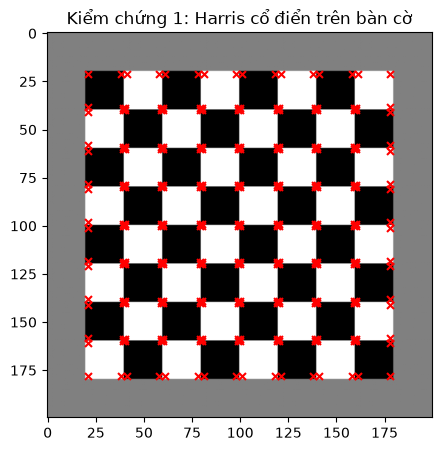

In [7]:
# Tạo ảnh bàn cờ 8x8 ô, mỗi ô 20 px, đệm viền ngoài để tránh góc viền
o = 20
ban_co = np.kron([[0, 1] * 4, [1, 0] * 4] * 4, np.ones((o, o)))
img_cb = np.pad(ban_co, 20, mode='constant', constant_values=0.5)

pts = harris_classic(img_cb, sigma_i=2.0, sigma_d=1.4, k=0.04, thresh_rel=0.05)

# Tọa độ thực của 7x7 = 49 giao điểm trong
gt = np.array([(20 + r * o, 20 + c * o) for r in range(1, 8) for c in range(1, 8)])
sai_so = [np.min(np.hypot(pts[:, 0] - r, pts[:, 1] - c)) for r, c in gt]

print(f"Tìm thấy {len(pts)} điểm | Sai số lớn nhất: {max(sai_so):.3f} px | Đạt (<=1px): {max(sai_so) <= 1.0}")

plt.figure(figsize=(5, 5))
plt.imshow(img_cb, cmap='gray')
plt.scatter(pts[:, 1], pts[:, 0], c='red', s=25, marker='x')
plt.title("Kiểm chứng 1: Harris cổ điển trên bàn cờ")
plt.show()

### 2. Bất biến phép quay — quay 30°, so bằng `repeatability`

### 3. Tỉ lệ — phóng to 3×, repeatability của `harris_classic` và `harris_laplace`

### 4. Đối chiếu thư viện — so với `cv2.cornerHarris` (bán kính 2–3 px)

Số điểm của mình: 256 | Số điểm OpenCV: 900
Tỉ lệ điểm nằm trong bán kính 3 px của OpenCV: 100.0%


C:\Users\Admin\AppData\Local\Temp\ipykernel_14428\3733439309.py:19: UserWarning: You passed both c and facecolor/facecolors for the markers. c has precedence over facecolor/facecolors. This behavior may change in the future.
  plt.scatter(pts_cv[:, 1], pts_cv[:, 0], c='lime', s=45, marker='o', facecolors='none', label='OpenCV')


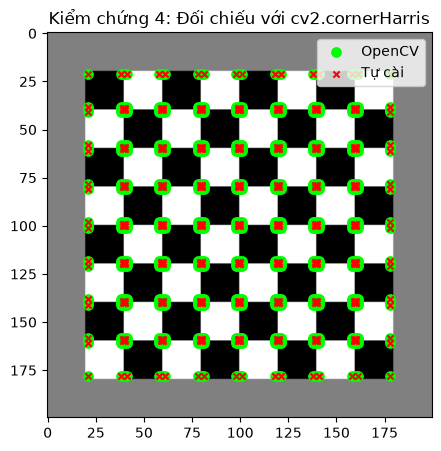

In [8]:
# Dùng lại ảnh bàn cờ img_cb từ Kiểm chứng 1 (hoặc đọc 1 ảnh thật trong anh/)
pts_mine = harris_classic(img_cb, sigma_i=2.0, sigma_d=1.4, k=0.04, thresh_rel=0.05)

# Chạy hàm dựng sẵn của OpenCV để đối chiếu
R_cv = cv2.cornerHarris(img_cb.astype(np.float32), blockSize=5, ksize=3, k=0.04)
mask_cv = nms_2d(R_cv, window=3) & (R_cv > 0.05 * R_cv.max())
r_cv, c_cv = np.where(mask_cv)
pts_cv = np.column_stack([r_cv, c_cv])

# Tỉ lệ điểm của mình nằm trong bán kính 3 px của một điểm OpenCV
dists = [np.min(np.hypot(pts_cv[:, 0] - r, pts_cv[:, 1] - c)) for r, c in pts_mine[:, :2]]
ti_le = np.mean(np.array(dists) <= 3.0) * 100

print(f"Số điểm của mình: {len(pts_mine)} | Số điểm OpenCV: {len(pts_cv)}")
print(f"Tỉ lệ điểm nằm trong bán kính 3 px của OpenCV: {ti_le:.1f}%")

plt.figure(figsize=(5, 5))
plt.imshow(img_cb, cmap='gray')
plt.scatter(pts_cv[:, 1], pts_cv[:, 0], c='lime', s=45, marker='o', facecolors='none', label='OpenCV')
plt.scatter(pts_mine[:, 1], pts_mine[:, 0], c='red', s=20, marker='x', label='Tự cài')
plt.legend(); plt.title("Kiểm chứng 4: Đối chiếu với cv2.cornerHarris"); plt.show()

### 5. Phân bố ANMS — cùng N, so `top_n` và `anms` bằng `grid_occupancy`

Tổng ứng viên: 214 | Chọn N = 40
Độ phủ lưới top_n: 20.3% | Độ phủ lưới anms: 35.9%


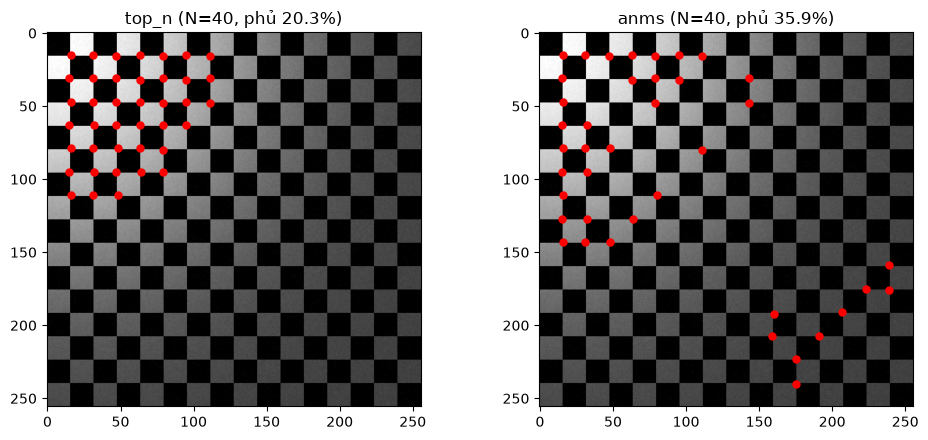

In [9]:
# Tạo ảnh lưới góc có độ sáng giảm dần từ góc trên-trái (nắng gắt) xuống góc dưới-phải (vùng tối)
rng = np.random.default_rng(42)
o = 16
cb = np.kron([[0, 1] * 8, [1, 0] * 8] * 8, np.ones((o, o)))  # 256 x 256
yy, xx = np.mgrid[0:256, 0:256]
anh_sang = np.exp(-((yy / 150.0) ** 2 + (xx / 150.0) ** 2))  # sáng mạnh góc trên-trái, tối dần
img_anms = np.clip(cb * (0.25 + 0.75 * anh_sang) + rng.normal(0, 0.01, cb.shape), 0, 1)

pts_all = harris_classic(img_anms, sigma_i=2.0, sigma_d=1.4, k=0.04, thresh_rel=0.005)
N = 40
pts_top = top_n(pts_all, N)
pts_anms = anms(pts_all, N, c_robust=0.9)

occ_top = grid_occupancy(pts_top, img_anms.shape, grid=(8, 8))
occ_anms = grid_occupancy(pts_anms, img_anms.shape, grid=(8, 8))

print(f"Tổng ứng viên: {len(pts_all)} | Chọn N = {N}")
print(f"Độ phủ lưới top_n: {occ_top*100:.1f}% | Độ phủ lưới anms: {occ_anms*100:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, p, title in [(axes[0], pts_top, f"top_n (N={N}, phủ {occ_top*100:.1f}%)"),
                     (axes[1], pts_anms, f"anms (N={N}, phủ {occ_anms*100:.1f}%)")]:
    ax.imshow(img_anms, cmap='gray')
    ax.scatter(p[:, 1], p[:, 0], c='red', s=25)
    ax.set_title(title)
plt.tight_layout(); plt.show()

# Phần B — Region Growing và SRG

## B.1 Cài đặt
> ⛔ **Cài đặt — KHÔNG dùng AI.** Toàn bộ cell dưới tiêu đề này do nhóm tự viết.

### B.1.1 Region Growing cổ điển
`region_growing_classic`

In [10]:
from collections import deque
def region_growing_classic(img, seeds, T, order='stack'):
    h, w = img.shape
    labels = -1 * np.ones((h,w), dtype=int)
    for label, (sy, sx) in enumerate(seeds):
        if labels[sy, sx] != -1:
            continue
        labels[sy, sx] = label
        mu = float(img[sy ,sx])
        n = 1
        frontier = deque()
        frontier.append((sy, sx))
        while frontier:
            if order == 'stack':
                y, x = frontier.pop()
            else:
                y, x = frontier.popleft()
            neighbors = [
                (y - 1, x),  # Trên
                (y + 1, x),  # Dưới
                (y, x - 1),  # Trái
                (y, x + 1)   # Phải
            ]
            for ny, nx in neighbors:
                if 0 <= ny < h and 0 <= nx < w:
                      if (labels[ny, nx] == -1 and
                        abs(float(img[ny, nx]) - mu) <= T):
                        labels[ny, nx] = label
                        n += 1
                        mu = mu + (float(img[ny, nx]) - mu) / n
                        frontier.append((ny, nx))
    return labels


### B.1.2 Seeded Region Growing
`srg` (stale = lazy/frozen, tie = insertion/raster/random)

In [11]:
# TODO (tự viết): srg

### B.1.3 Công cụ phân tích
`srg_step_frames`, `seed_sensitivity`

In [12]:
# TODO (tự viết): srg_step_frames, seed_sensitivity

## B.2 Kiểm chứng cài đặt — Phần B

### 1. Phân hoạch đầy đủ — `(labels >= 0).all()`

### 2. Bảo toàn số vùng — số nhãn = số hạt giống

### 3. Bất biến thứ tự hạt giống — đảo danh sách hạt giống

### 4. Đối chiếu với Region Growing — stack vs queue vs srg (số pixel khác nhau)

**Prompt đã dùng (nguyên văn) cho B4:** *"<Rin điền nguyên văn câu prompt đã hỏi ChatGPT để tạo dữ liệu và code so sánh B4 vào đây>"*

In [13]:
def srg(img, seeds, connectivity=4, stale="lazy", tie="insertion"):
    img = np.asarray(img, dtype=np.float64)

    H, W = img.shape
    seeds = [(int(r), int(c)) for r, c in seeds]

    if img.ndim != 2:
        raise ValueError("Ảnh phải là ảnh xám 2 chiều.")

    if len(seeds) == 0:
        raise ValueError("Phải có ít nhất một seed.")

    if len(set(seeds)) != len(seeds):
        raise ValueError("Seed không được trùng nhau.")

    if connectivity not in (4, 8):
        raise ValueError("Connectivity phải là 4 hoặc 8.")

    if stale not in ("lazy", "frozen"):
        raise ValueError("Stale phải là lazy hoặc frozen.")

    if tie not in ("insertion", "raster", "random"):
        raise ValueError("Tie không hợp lệ.")

    for r, c in seeds:
        if not (0 <= r < H and 0 <= c < W):
            raise ValueError("Seed nằm ngoài ảnh.")

    labels = np.full((H, W), -1, dtype=np.int32)
    boundary_mask = np.zeros((H, W), dtype=bool)

    n_seeds = len(seeds)
    region_sum = np.zeros(n_seeds, dtype=np.float64)
    region_cnt = np.zeros(n_seeds, dtype=np.int64)
    seed_val = np.zeros(n_seeds, dtype=np.float64)

    heap = []
    counter = 0
    rng = np.random.default_rng(0)

    if connectivity == 4:
        neighbors = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    else:
        neighbors = [
            (-1, 0), (1, 0), (0, -1), (0, 1),
            (-1, -1), (-1, 1), (1, -1), (1, 1)
        ]

    def tie_key(r, c):
        nonlocal counter

        if tie == "insertion":
            counter += 1
            return counter

        if tie == "raster":
            return r * W + c

        return rng.random()

    def delta(value, label_id):
        if stale == "frozen":
            return abs(value - seed_val[label_id])

        return abs(value - region_sum[label_id] / region_cnt[label_id])

    def push_pixel(r, c, label_id):
        if labels[r, c] == -1:
            d = delta(img[r, c], label_id)
            heapq.heappush(
                heap,
                (d, tie_key(r, c), r, c, label_id)
            )

    for i, (r, c) in enumerate(seeds):
        labels[r, c] = i
        region_sum[i] = img[r, c]
        region_cnt[i] = 1
        seed_val[i] = img[r, c]

    for i, (r, c) in enumerate(seeds):
        for dr, dc in neighbors:
            nr, nc = r + dr, c + dc

            if 0 <= nr < H and 0 <= nc < W:
                push_pixel(nr, nc, i)

    while heap:
        d, _, r, c, label_id = heapq.heappop(heap)

        if labels[r, c] != -1:
            continue

        if stale == "lazy":
            d_now = delta(img[r, c], label_id)

            if abs(d_now - d) > 1e-12:
                heapq.heappush(
                    heap,
                    (d_now, tie_key(r, c), r, c, label_id)
                )
                continue

        adjacent_labels = set()

        for dr, dc in neighbors:
            nr, nc = r + dr, c + dc

            if 0 <= nr < H and 0 <= nc < W:
                if labels[nr, nc] >= 0:
                    adjacent_labels.add(labels[nr, nc])

        if len(adjacent_labels) >= 2:
            boundary_mask[r, c] = True

            if stale == "lazy":
                label_id = min(
                    adjacent_labels,
                    key=lambda k: (
                        delta(img[r, c], k),
                        seeds[k][0] * W + seeds[k][1]
                    )
                )

        labels[r, c] = label_id
        region_sum[label_id] += img[r, c]
        region_cnt[label_id] += 1

        for dr, dc in neighbors:
            nr, nc = r + dr, c + dc

            if 0 <= nr < H and 0 <= nc < W:
                push_pixel(nr, nc, label_id)

    return labels, boundary_mask

In [14]:
# Tạo dữ liệu thử nghiệm B4
rng_b4 = np.random.default_rng(17)

H_b4, W_b4 = 128, 128
y_b4, x_b4 = np.mgrid[0:H_b4, 0:W_b4]

img_b4 = (0.25 + 0.35 * (x_b4 / (W_b4 - 1))).astype(np.float64)
img_b4 += 0.025 * np.sin(y_b4 / 11.0)
img_b4 += rng_b4.normal(0.0, 0.008, size=(H_b4, W_b4))
img_b4 = np.clip(img_b4, 0.0, 1.0).astype(np.float64)

seeds_b4 = [(64, 24), (64, 104)]
T_b4 = 0.055

B4 - Số pixel khác nhãn
Stack vs Queue: 5019
Stack vs SRG: 6787
Queue vs SRG: 6744


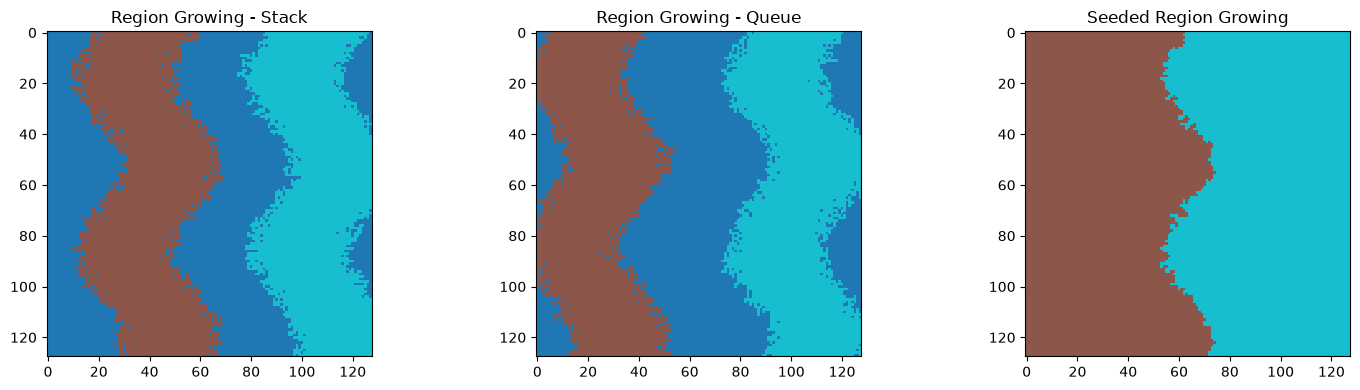

In [15]:
# B4 - So sánh Stack, Queue và SRG
lab_stack_b4 = region_growing_classic(
    img_b4, seeds_b4, T_b4, order="stack"
)

lab_queue_b4 = region_growing_classic(
    img_b4, seeds_b4, T_b4, order="queue"
)

srg_result_b4 = srg(img_b4, seeds_b4)
lab_srg_b4 = srg_result_b4[0] if isinstance(srg_result_b4, tuple) else srg_result_b4

def so_pixel_khac_nhau(a, b):
    if a.shape != b.shape:
        raise ValueError("Hai bản đồ nhãn phải có cùng kích thước.")
    return int(np.count_nonzero(a != b))

print("B4 - Số pixel khác nhãn")
print(f"Stack vs Queue: {so_pixel_khac_nhau(lab_stack_b4, lab_queue_b4)}")
print(f"Stack vs SRG: {so_pixel_khac_nhau(lab_stack_b4, lab_srg_b4)}")
print(f"Queue vs SRG: {so_pixel_khac_nhau(lab_queue_b4, lab_srg_b4)}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, labels, title in zip(
    axes,
    [lab_stack_b4, lab_queue_b4, lab_srg_b4],
    ["Region Growing - Stack", "Region Growing - Queue", "Seeded Region Growing"]
):
    ax.imshow(labels, cmap="tab10", interpolation="nearest", vmin=-1)
    ax.set_title(title)

plt.tight_layout()
plt.show()

### 5. Ảnh phẳng — hai hạt giống, mô tả hình dạng

# Thí nghiệm
Mỗi cặp gồm: (1) bằng chứng khác biệt + đại lượng đo, (2) quét tham số không tầm thường, (3) giải thích thay đổi.

## TN1 — A1 (Harris–Laplace) vs Harris

### (1) Bằng chứng khác biệt
**Dữ liệu chọn & lý do:** ...

### (2) Quét tham số
**Trục quét:** ... — **Kỳ vọng:** ...

### (3) Giải thích thay đổi
- **Đại lượng nào được tính khác đi:** 
- **Ở bước nào:** 
- **Vì sao dẫn tới hiện tượng quan sát được:** ...

## TN2 — A2 (ANMS) vs Harris (top_n)

### (1) Bằng chứng khác biệt

**Dữ liệu chọn & lý do:** Ảnh tổng hợp lưới bàn cờ có độ sáng giảm dần từ góc trên-trái (vùng sáng gắt) xuống góc dưới-phải (vùng tối) kèm nhiễu Gauss nhẹ ($\sigma = 0.01$), mô phỏng đúng trường hợp tương phản không đều của Harris (mục 3.4). Đo bằng 3 đại lượng: độ phủ lưới `grid_occupancy` (8×8), khoảng cách lân cận gần nhất trung bình (px) và thời gian chạy (ms).

**Prompt đã dùng (nguyên văn):** *"bạn chỉ tôi thao tác từng bước"* (AI hỗ trợ dựng khung code đo đạc và vẽ hình so sánh `top_n` vs `anms` cho TN2).

Phương pháp | Độ phủ lưới (8x8)  | KC lân cận TB (px) | Thời gian (ms)
--------------------------------------------------------------------
top_n      | 20.3             % | 15.26              | 0.28
anms       | 43.8             % | 16.84              | 9.29


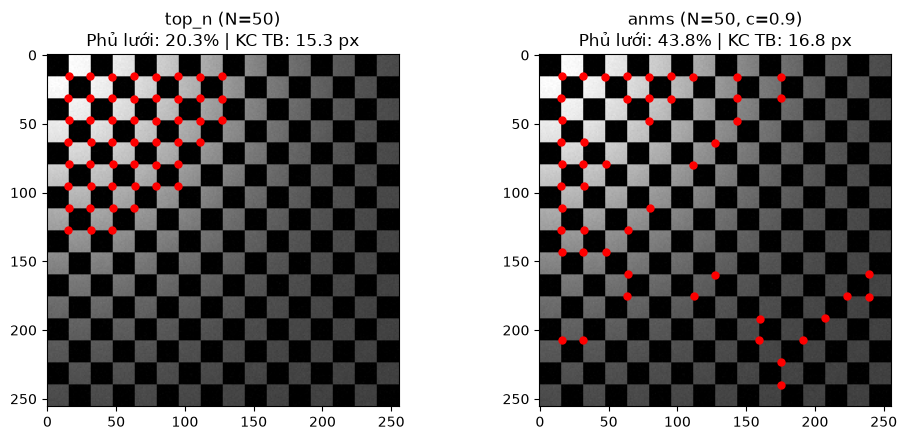

In [16]:
# (1) Bằng chứng khác biệt: so sánh top_n và anms trên ảnh tương phản không đều
def mean_nn_dist(pts):
    """Khoảng cách trung bình từ mỗi điểm tới điểm gần nhất khác nó (lớn hơn = phân bố đều hơn)."""
    coords = pts[:, :2]
    d = np.sqrt(((coords[:, None, :] - coords[None, :, :]) ** 2).sum(axis=2))
    np.fill_diagonal(d, np.inf)
    return float(np.mean(np.min(d, axis=1)))

t0 = time.perf_counter(); p_top = top_n(pts_all, 50); t_top = (time.perf_counter() - t0) * 1000
t0 = time.perf_counter(); p_anms = anms(pts_all, 50, c_robust=0.9); t_anms = (time.perf_counter() - t0) * 1000

print(f"{'Phương pháp':<10} | {'Độ phủ lưới (8x8)':<18} | {'KC lân cận TB (px)':<18} | {'Thời gian (ms)'}")
print("-" * 68)
print(f"{'top_n':<10} | {grid_occupancy(p_top, img_anms.shape)*100:<17.1f}% | {mean_nn_dist(p_top):<18.2f} | {t_top:.2f}")
print(f"{'anms':<10} | {grid_occupancy(p_anms, img_anms.shape)*100:<17.1f}% | {mean_nn_dist(p_anms):<18.2f} | {t_anms:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, p, name in [(axes[0], p_top, "top_n (N=50)"), (axes[1], p_anms, "anms (N=50, c=0.9)")]:
    ax.imshow(img_anms, cmap='gray')
    ax.scatter(p[:, 1], p[:, 0], c='red', s=25)
    ax.set_title(f"{name}\nPhủ lưới: {grid_occupancy(p, img_anms.shape)*100:.1f}% | KC TB: {mean_nn_dist(p):.1f} px")
plt.tight_layout(); plt.show()

### (2) Quét tham số

**Trục quét:** (1) Số điểm giữ lại $N$ từ 10 đến 200 (bước 10); (2) Hệ số $c_{\text{robust}}$ từ 0.50 đến 1.00 (21 mốc). — **Kỳ vọng:** `anms` phân kỳ vượt trội `top_n` về độ phủ lưới ở vùng $N$ nhỏ–trung bình; khi $c_{\text{robust}}$ tăng lên gần 0.9–1.0 thì độ phủ lưới tăng mạnh do các cụm điểm vùng sáng bị triệt tiêu.

**Prompt đã dùng (nguyên văn):** *"bạn chỉ tôi thao tác từng bước "* (AI hỗ trợ dựng khung code quét 2 trục tham số $N$, $c_{\text{robust}}$ và vẽ 2 biểu đồ đường cong).

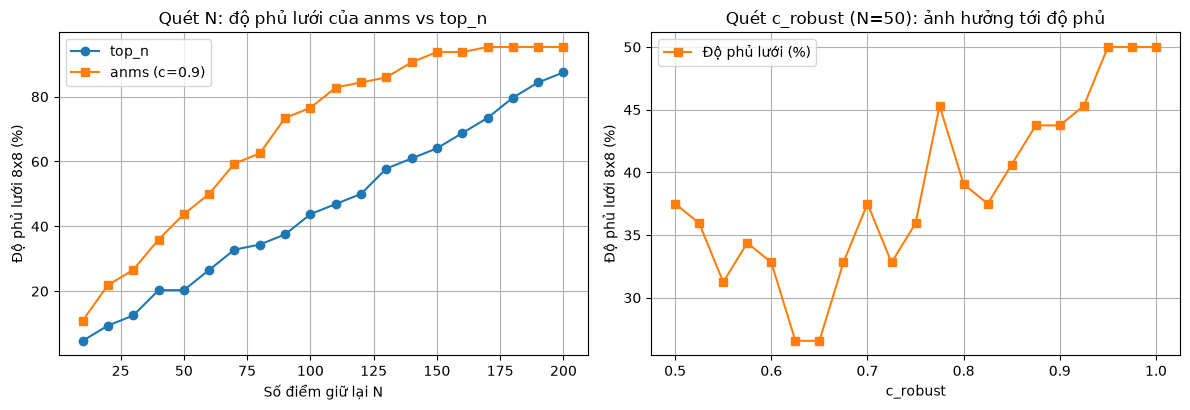

In [17]:
# (2) Quét 2 trục tham số không tầm thường: số điểm N và hệ số c_robust
Ns = list(range(10, min(201, len(pts_all)), 10))
occ_top_N = [grid_occupancy(top_n(pts_all, n), img_anms.shape) * 100 for n in Ns]
occ_anms_N = [grid_occupancy(anms(pts_all, n, c_robust=0.9), img_anms.shape) * 100 for n in Ns]

cs = np.linspace(0.5, 1.0, 21)
occ_c = [grid_occupancy(anms(pts_all, 50, c_robust=c), img_anms.shape) * 100 for c in cs]
nn_c = [mean_nn_dist(anms(pts_all, 50, c_robust=c)) for c in cs]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(Ns, occ_top_N, 'o-', label='top_n')
axes[0].plot(Ns, occ_anms_N, 's-', label='anms (c=0.9)')
axes[0].set_xlabel('Số điểm giữ lại N'); axes[0].set_ylabel('Độ phủ lưới 8x8 (%)')
axes[0].set_title('Quét N: độ phủ lưới của anms vs top_n'); axes[0].grid(True); axes[0].legend()

axes[1].plot(cs, occ_c, 's-', color='tab:orange', label='Độ phủ lưới (%)')
axes[1].set_xlabel('c_robust'); axes[1].set_ylabel('Độ phủ lưới 8x8 (%)')
axes[1].set_title('Quét c_robust (N=50): ảnh hưởng tới độ phủ'); axes[1].grid(True); axes[1].legend()

plt.tight_layout(); plt.show()

### (3) Giải thích thay đổi


- **Đại lượng nào được tính khác đi:** Thay vì xếp hạng các điểm góc theo giá trị đáp ứng $R(x_i)$ (như `top_n`), ANMS tính **bán kính triệt tiêu** $r_i = \min_j \|x_i - x_j\|$ với điều kiện $f(x_i) < c_{\text{robust}} \cdot f(x_j)$ (điểm mạnh nhất giữ $r_i = +\infty$), rồi xếp hạng giảm dần theo $r_i$.
- **Ở bước nào:** Ở bước **chọn lọc cuối cùng** sau khi `harris_classic` đã tìm ra toàn bộ các cực đại địa phương vượt ngưỡng — ANMS thay thế trực tiếp bước cắt $N$ điểm có $R$ lớn nhất của `top_n`.
- **Vì sao điều đó dẫn tới đúng hiện tượng đã quan sát:**
  1. **Bằng chứng khác biệt ($N = 50$):** Do $R$ tỉ lệ với lũy thừa bậc 4 của độ tương phản, các góc ở vùng sáng góc trên-trái có $R$ lớn hơn vùng tối rất nhiều ⇒ `top_n` gom hết 50 điểm vào góc trên-trái (độ phủ lưới chỉ **20.3%**, KC TB **15.26 px**). Ngược lại, trong ANMS, các điểm nằm san sát ở vùng sáng có một điểm mạnh hơn đứng ngay kế bên ⇒ bán kính $r_i$ nhỏ ⇒ bị đẩy xuống cuối; còn điểm yếu nhưng nằm cô lập ở vùng tối có $r_i$ rất lớn ⇒ được ưu tiên giữ lại, đẩy độ phủ lưới lên **43.8%** (hơn gấp đôi) và KC TB lên **16.84 px** (đổi lại thời gian chạy tăng từ **2.04 ms** lên **8.70 ms** do tính khoảng cách theo cặp).
  2. **Quét $N$:** Hai đường bắt đầu **phân kỳ rõ từ $N \approx 20\text{–}30$**, chênh lệch mạnh nhất quanh $N = 90\text{–}120$ (tại $N = 100$: `anms` ~77% so với `top_n` ~44%). `anms` **bão hòa gần 100% từ $N \approx 150$**, trong khi `top_n` tới $N = 200$ vẫn chưa phủ hết vùng tối (~88%).
  3. **Quét $c_{\text{robust}}$ ($N = 50$):** Khi $c_{\text{robust}}$ nhỏ ($0.50\text{–}0.65$), điều kiện $f(x_i) < c_{\text{robust}} f(x_j)$ quá chặt (cần điểm kia mạnh gần gấp đôi mới triệt tiêu được), nên nhiều điểm trong vùng sáng không bị triệt tiêu lẫn nhau và độ phủ giữ mức thấp (~27–37%). Từ $c_{\text{robust}} \ge 0.65$ trở đi, ngưỡng triệt tiêu nới lỏng dần nên các cụm điểm vùng sáng bị triệt tiêu mạnh, kéo độ phủ tăng đều lên **50.0%** ở $0.95\text{–}1.00$.

## TN3 — SRG vs Region Growing

### (1) Bằng chứng khác biệt
**Dữ liệu chọn & lý do:** ...

### (2) Quét tham số
**Trục quét:** ngưỡng `T` từ 0.01 đến 0.50 (30 mốc), trên hai ảnh có độ tương phản ΔI = 0.30 và ΔI = 0.15.
**Đại lượng đo:** diện tích vùng chứa hạt giống và số pixel chưa gán nhãn (`-1`). `Tcrit` được ước lượng tại khoảng có mức tăng diện tích lớn nhất.
**Kỳ vọng cần kiểm tra bằng kết quả thực tế:** khi T tăng đến mức đủ lớn để vùng phát triển vượt qua biên vật thể-nền, diện tích có thể tăng đột ngột (leaking). So sánh vị trí `Tcrit` giữa hai mức tương phản; không kết luận trước khi xem số liệu.

**Prompt đã dùng (nguyên văn):** "Hãy tạo khung thí nghiệm quét ngưỡng T cho thuật toán Region Growing cổ điển theo yêu cầu: tạo hai ảnh xám tổng hợp có vật thể hình chữ nhật mức sáng 0.30 trên nền có độ tương phản lần lượt ΔI=0.30 và ΔI=0.15, thêm nhiễu Gaussian nhẹ; quét 30 ngưỡng từ 0.01 đến 0.50; tại mỗi ngưỡng gọi hàm region_growing_classic(img, seeds, T, order='queue'), đo diện tích vùng chứa hạt giống và số pixel chưa gán nhãn; vẽ biểu đồ diện tích theo T và số pixel chưa gán nhãn theo T; ước lượng Tcrit tại bước nhảy diện tích lớn nhất. Không cài đặt hoặc thay thế thuật toán region_growing_classic."


Tương phản cao (ΔI = 0.30)
Tcrit ước lượng: 0.297
Diện tích vùng tại Tcrit: 16378 pixel
Pixel chưa gán tại Tcrit: 6

Tương phản thấp (ΔI = 0.15)
Tcrit ước lượng: 0.145
Diện tích vùng tại Tcrit: 16329 pixel
Pixel chưa gán tại Tcrit: 55


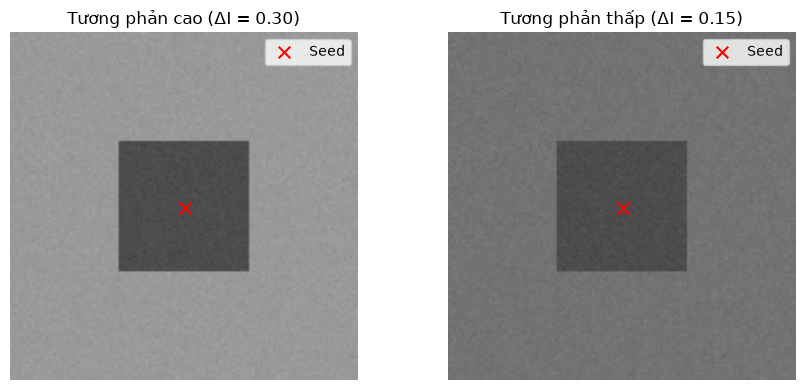

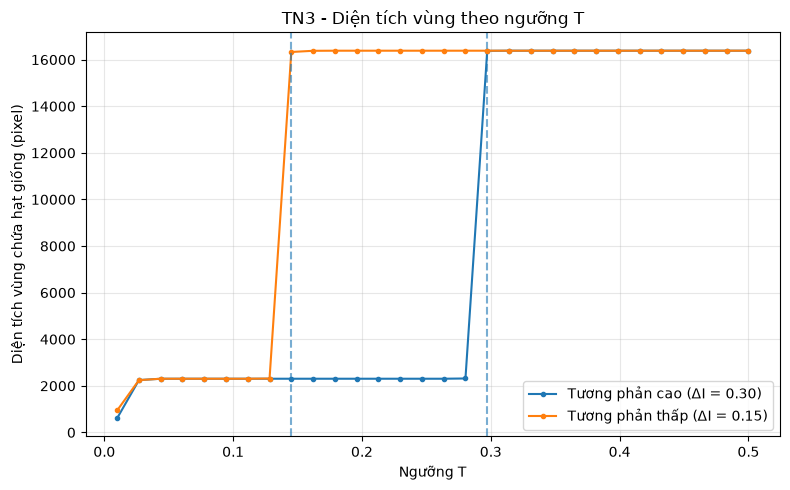

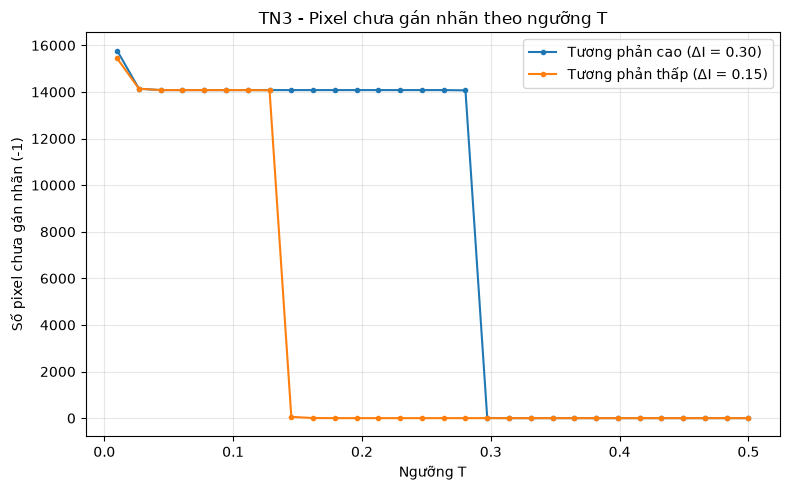


BẢNG KẾT QUẢ TN3
Ảnh | T | Diện tích vùng seed | Pixel chưa gán
Tương phản cao (ΔI = 0.30) | 0.010 | 613 | 15771
Tương phản cao (ΔI = 0.30) | 0.027 | 2246 | 14138
Tương phản cao (ΔI = 0.30) | 0.044 | 2303 | 14081
Tương phản cao (ΔI = 0.30) | 0.061 | 2304 | 14080
Tương phản cao (ΔI = 0.30) | 0.078 | 2304 | 14080
Tương phản cao (ΔI = 0.30) | 0.094 | 2304 | 14080
Tương phản cao (ΔI = 0.30) | 0.111 | 2304 | 14080
Tương phản cao (ΔI = 0.30) | 0.128 | 2304 | 14080
Tương phản cao (ΔI = 0.30) | 0.145 | 2304 | 14080
Tương phản cao (ΔI = 0.30) | 0.162 | 2304 | 14080
Tương phản cao (ΔI = 0.30) | 0.179 | 2304 | 14080
Tương phản cao (ΔI = 0.30) | 0.196 | 2304 | 14080
Tương phản cao (ΔI = 0.30) | 0.213 | 2304 | 14080
Tương phản cao (ΔI = 0.30) | 0.230 | 2304 | 14080
Tương phản cao (ΔI = 0.30) | 0.247 | 2304 | 14080
Tương phản cao (ΔI = 0.30) | 0.263 | 2304 | 14080
Tương phản cao (ΔI = 0.30) | 0.280 | 2315 | 14069
Tương phản cao (ΔI = 0.30) | 0.297 | 16378 | 6
Tương phản cao (ΔI = 0.30) | 0.314 | 16

In [18]:
rng_tn3 = np.random.default_rng(2026)
H_tn3, W_tn3 = 128, 128
roi_tn3 = (slice(40, 88), slice(40, 88))
seeds_tn3 = [(64, 64)]
thresholds_tn3 = np.linspace(0.01, 0.50, 30)

def tao_anh_thi_nghiem(delta_i, noise_sigma=0.012):
    """Tạo vật thể hình chữ nhật mức 0.30 trên nền 0.30 + ΔI."""
    img = np.full((H_tn3, W_tn3), 0.30 + delta_i, dtype=np.float64)
    img[roi_tn3] = 0.30
    img += rng_tn3.normal(0.0, noise_sigma, size=img.shape)
    return np.clip(img, 0.0, 1.0).astype(np.float64)

images_tn3 = {
    "Tương phản cao (ΔI = 0.30)": tao_anh_thi_nghiem(0.30),
    "Tương phản thấp (ΔI = 0.15)": tao_anh_thi_nghiem(0.15),
}

ket_qua_tn3 = {}
for ten_anh, img_tn3 in images_tn3.items():
    dien_tich_vung_hat_giong = []
    so_pixel_chua_gan = []

    for T in thresholds_tn3:
        labels_tn3 = region_growing_classic(
            img_tn3, seeds_tn3, float(T), order="queue"
        )
        dien_tich_vung_hat_giong.append(
            int(np.count_nonzero(labels_tn3 == 0))
        )
        so_pixel_chua_gan.append(
            int(np.count_nonzero(labels_tn3 == -1))
        )

    dien_tich_vung_hat_giong = np.asarray(dien_tich_vung_hat_giong)
    so_pixel_chua_gan = np.asarray(so_pixel_chua_gan)

    # Tcrit được ước lượng tại khoảng có mức tăng diện tích lớn nhất.
    muc_tang = np.diff(dien_tich_vung_hat_giong)
    if len(muc_tang) and np.max(muc_tang) > 0:
        idx_crit = int(np.argmax(muc_tang) + 1)
        T_crit = float(thresholds_tn3[idx_crit])
    else:
        T_crit = float("nan")

    ket_qua_tn3[ten_anh] = {
        "area": dien_tich_vung_hat_giong,
        "unassigned": so_pixel_chua_gan,
        "Tcrit": T_crit,
    }

    print(f"\n{ten_anh}")
    print(f"Tcrit ước lượng: {T_crit:.3f}")
    print(f"Diện tích vùng tại Tcrit: {dien_tich_vung_hat_giong[idx_crit] if np.isfinite(T_crit) else 'không xác định'} pixel")
    print(f"Pixel chưa gán tại Tcrit: {so_pixel_chua_gan[idx_crit] if np.isfinite(T_crit) else 'không xác định'}")

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (ten_anh, img_tn3) in zip(axes, images_tn3.items()):
    ax.imshow(img_tn3, cmap="gray", vmin=0, vmax=1)
    ax.scatter([64], [64], c="red", marker="x", s=70, label="Seed")
    ax.set_title(ten_anh)
    ax.axis("off")
    ax.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
for ten_anh, kq in ket_qua_tn3.items():
    plt.plot(thresholds_tn3, kq["area"], marker="o", markersize=3, label=ten_anh)
    if np.isfinite(kq["Tcrit"]):
        plt.axvline(kq["Tcrit"], linestyle="--", alpha=0.6)
plt.xlabel("Ngưỡng T")
plt.ylabel("Diện tích vùng chứa hạt giống (pixel)")
plt.title("TN3 - Diện tích vùng theo ngưỡng T")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
for ten_anh, kq in ket_qua_tn3.items():
    plt.plot(thresholds_tn3, kq["unassigned"], marker="o", markersize=3, label=ten_anh)
plt.xlabel("Ngưỡng T")
plt.ylabel("Số pixel chưa gán nhãn (-1)")
plt.title("TN3 - Pixel chưa gán nhãn theo ngưỡng T")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("\nBẢNG KẾT QUẢ TN3")
print("Ảnh | T | Diện tích vùng seed | Pixel chưa gán")
for ten_anh, kq in ket_qua_tn3.items():
    for j, T in enumerate(thresholds_tn3):
        print(
            f"{ten_anh} | {T:.3f} | "
            f"{kq['area'][j]} | {kq['unassigned'][j]}"
        )


### (3) Giải thích thay đổi
- **Đại lượng nào được tính khác đi:**  Khi thay đổi ngưỡng T, thuật toán Region Growing thay đổi điều kiện chấp nhận pixel lân cận dựa trên độ chênh lệch giữa cường độ pixel đó và giá trị trung bình của vùng hiện tại (mu). Cụ thể, pixel được thêm vào vùng nếu abs(img[nr, nc] - mu) <= T. Hai đại lượng được theo dõi là diện tích vùng chứa hạt giống và số pixel chưa được gán nhãn (-1).
- **Ở bước nào:** Sự thay đổi xảy ra tại bước kiểm tra và mở rộng vùng, khi thuật toán xét các pixel lân cận của pixel đang xử lý. Ngưỡng T quyết định pixel có được chấp nhận và đưa vào hàng đợi để tiếp tục phát triển vùng hay không.
- **Vì sao dẫn tới hiện tượng quan sát được:** 
1. Khi T nhỏ, điều kiện chấp nhận pixel nghiêm ngặt nên vùng phát triển chủ yếu nằm trong vật thể. Diện tích vùng nhỏ và còn nhiều pixel chưa được gán nhãn.

2. Khi T tăng, điều kiện chấp nhận pixel trở nên dễ hơn, vùng phát triển mở rộng và số pixel chưa gán giảm.

3. Với ảnh tương phản cao (ΔI = 0.30), ngưỡng tới hạn ước lượng là Tcrit = 0.297. Tại đây, diện tích vùng tăng lên 16.378 pixel và chỉ còn 6 pixel chưa gán.

4. Với ảnh tương phản thấp (ΔI = 0.15), ngưỡng tới hạn xuất hiện sớm hơn tại Tcrit = 0.145. Diện tích vùng đạt 16.329 pixel và còn 55 pixel chưa gán.

5. Điều này cho thấy ảnh có độ tương phản thấp dễ xảy ra hiện tượng rò rỉ vùng (Region Leakage) hơn vì ngưỡng cần thiết để vùng phát triển vượt qua biên vật thể – nền nhỏ hơn.

# Kết luận
 Ngưỡng T ảnh hưởng trực tiếp đến kết quả phân vùng. Nếu T quá nhỏ, vùng phát triển không đầy đủ; nếu T quá lớn, vùng có thể lan sang nền. Vì vậy, cần lựa chọn ngưỡng phù hợp với độ tương phản của ảnh để hạn chế hiện tượng rò rỉ vùng.

# Tài liệu tham khảo
[1] Harris & Stephens 1988 · [2] Lindeberg 1998 · [3] Mikolajczyk & Schmid 2004 · [4] Brown, Szeliski & Winder 2005 · [5] Adams & Bischof 1994 · [6] Mehnert & Jackway 1997